**Import Libraries**

In [2]:
#algorithms as requested:
from implementations import mean_squared_error_gd, mean_squared_error_sgd, least_squares, ridge_regression, logistic_regression,  reg_logistic_regression
from preprocessing import parse_dict_to_matrix, subsetting_data, split_data
#list of python standard libraries, all available without needing pip install
import collections
import csv
import numpy as np
#for data visualization purposes:
import matplotlib as plt

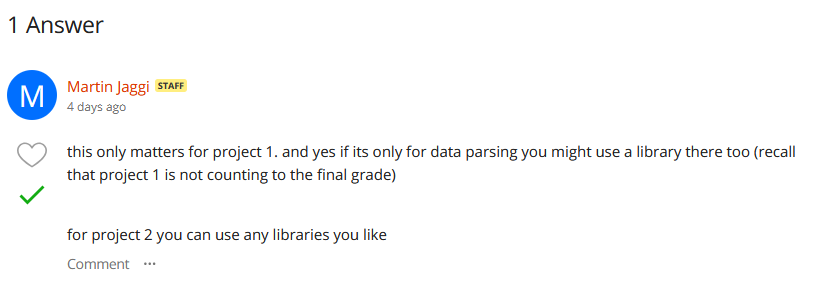

Since csv is a python native library that doesn't need to be pip installed, we judge it is more fitting of the taste of 'np-only' style of this project.

In [3]:
# Initialize a dictionary that automatically creates lists for new keys
# Avoid the shadowed built-in name `list`
def build_dataset(p):
    all_columns = collections.defaultdict(lambda: [])

    # Read the CSV natively
    with open(p, mode="r", encoding="utf-8", newline="") as f:
        reader = csv.DictReader(f)
        
        for row in reader:
            for column_name, value in row.items():
                all_columns[column_name].append(value)

    # Convert lists to NumPy arrays for your ML pipeline
    # (Note: You may need to specify dtype=float if the columns are numeric, 
    # because CSV reads everything as strings by default)
    dataset = {}
    for column_name, values_list in all_columns.items():
        dataset[column_name] = np.array(values_list)

    # Now you have a native, zero-external-dependency {column: np.array} structure!
    print("Total features extracted:", len(dataset.keys()))
    return dataset

In [4]:
# change to your respective dataset paths
X_all = build_dataset(r"E:\EPFL_CS433_P1\data\x_train.csv")
y = build_dataset(r"E:\EPFL_CS433_P1\data\y_train.csv")

Total features extracted: 322
Total features extracted: 2


In [5]:
y.keys()

dict_keys(['Id', '_MICHD'])

In [6]:
y_vector = y['_MICHD']

In [7]:
y['_MICHD'][2603]

np.str_('-1')

In [8]:
positive_perc = np.sum(y['_MICHD']=='1')/len(y['_MICHD'])
print(f'The MICHD positive patients only consists of {positive_perc}. of the sampled population')

The MICHD positive patients only consists of 0.08830207079403295. of the sampled population


Right of the bat this low % tells me that I am dealing with a bit of a class-imbalance data, where defaulted model can achieve their ability to predict well by simply spamming null conditions. If I have a very naive model that simply ignores all features and produce 0 as a prediction every-time, based off of this 328135 sample I would only be making mistakes 8.83% of the time. This means 1) precision is a bad metric to be looked at, probably ROC under the curve is better; 2) Practicing the safe assumption of the medical professionals, I should be more easy with making false-positive diagnosis than making false-negative prediction errors. 
With these in mind, let's approach our binary classification. 

In [9]:
X_all.keys()

dict_keys(['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'EXERA

In [10]:
#Import custom data cleaning methods
from preprocessing import shape

In [11]:
shape(X_all)

(328135, 322)

Naive Feature Engineering: Capture only the main block.

The idea is simple -- there's 300 + features across two different type of survey and multiple questionaire variations on state questions. 
We want to first predict the final medical outcome based on the main-block, which is placed in the front of every survey, captures the most attention, and is directly health related. 
Speicifically we want to find and justify our choice of variables by plotting distributions of choice features P(X | Y=0) and P(X | Y=1), where they maximally separate from each other.

In [12]:
#all features
X_all.keys()

dict_keys(['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'EXERA

In [13]:
#Main health variables
health_list = ['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'EXERANY2', 'EXRACT11', 'EXEROFT1', 'EXERHMM1', 'EXRACT21', 'EXEROFT2', 'EXERHMM2', 'STRENGTH', 'SEATBELT', 'HTIN4', 'HTM4', 'WTKG3', '_BMI5', '_BMI5CAT', '_RFBMI5', '_SMOKER3', 'RFSMOK3', 'DRNKANY5', 'DROCDY3', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_TOTINDA']

In [14]:
def subsetting_data (dataset, featurelist):
    '''
    expect dataset in column major order as a dictionary of np.arrays, while featureset should be a list of strings that spans dataset.keys()
    '''
    sub_dataset = {}
    for column_name in featurelist:
        if column_name in dataset:
            sub_dataset[column_name] = dataset[column_name]

    return sub_dataset

In [15]:
 
health_subset = subsetting_data(X_all, health_list)

In [16]:
health_subset.keys()

dict_keys(['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'EXERANY2', 'EXRACT11', 'EXEROFT1', 'EXERHMM1', 'EXRACT21', 'EXEROFT2', 'EXERHMM2', 'STRENGTH', 'SEATBELT', 'HTIN4', 'HTM4', 'WTKG3', '_BMI5', '_BMI5CAT', '_RFBMI5', '_SMOKER3', 'DRNKANY5', '_RFBING5', '_DRNKWEK', '_RFDRHV5', '_TOTINDA'])

In [17]:
short_list = ['GENHLTH','PHYSHLTH','MENTHLTH']
short_subset = subsetting_data(X_all, short_list)
short_subset

{'GENHLTH': array(['2', '4', '2', ..., '3', '3', '2'], shape=(328135,), dtype='<U1'),
 'PHYSHLTH': array(['1', '88', '77', ..., '88', '88', '7'],
       shape=(328135,), dtype='<U2'),
 'MENTHLTH': array(['5', '88', '77', ..., '1', '88', '7'], shape=(328135,), dtype='<U2')}

In [18]:
import numpy as np

feature_columns = []

for key in short_subset:
    # 1. Clean up spaces
    str_arr = np.char.strip(short_subset[key])
    
    # 2. Identify where empty strings exist
    empty_mask = (str_arr == '')
    
    # 3. Initialize a float array directly, avoiding string truncation completely
    # We fill it with zeros first, then populate it
    float_arr = np.zeros(str_arr.shape, dtype=float)
    
    # Fill the valid (non-empty) entries by converting them to float
    float_arr[~empty_mask] = str_arr[~empty_mask].astype(float)
    
    # Fill the empty entries with np.nan so we can find them
    float_arr[empty_mask] = np.nan
    
    # 4. Impute the NaNs with the column mean so matrix math works
    nan_mask = np.isnan(float_arr)
    if np.any(nan_mask):
        # Calculate mean of the valid numbers in this column
        if np.any(~nan_mask):
            valid_mean = np.mean(float_arr[~nan_mask])
        else:
            valid_mean = 0.0 # If the entire column was empty strings
        float_arr[nan_mask] = valid_mean
        
    feature_columns.append(float_arr)

# Stack them into NxD matrix
tx = np.column_stack(feature_columns)
print("Matrix shape:", tx.shape)


Matrix shape: (328135, 3)


In [19]:
tx, features = parse_dict_to_matrix(short_subset)

print("Matrix shape:", tx.shape)
print("Features ordered:", features)

Matrix shape: (328135, 3)
Features ordered: ['GENHLTH', 'PHYSHLTH', 'MENTHLTH']


In [20]:
len(health_subset.keys())/ len(X_all.keys())

0.12732919254658384

In [21]:
#make sure every id is unique
len(np.unique(X_all['Id'])) == len((X_all['Id']))

True

** Data Spliting for K-FOLD Cross-Validation**

to be developed

**Try out Implementation on a Subset of Data**

** Handling Class Imbalance through random-subsampling **


** Comparison of Multiple Linear Methods we Implemented **

In [22]:
# Assuming y_vector currently contains string elements like '1', '2', or '-1'
y_numeric = y_vector.astype(float).astype(int)

# Map BRFSS convention: 
# Usually, in BRFSS, 1 = Yes (Heart Disease), 2 = No (No Heart Disease)
# Let's check what values you have. If you have 1 and 2:
if 2 in np.unique(y_numeric):
    # Map 2 (No) to 0, and keep 1 (Yes) as 1
    y_clean = np.where(y_numeric == 2, 0, y_numeric)
    # Ensure any -1 or unexpected values also become 0
    y_clean[y_clean < 0] = 0
else:
    # If it's already 0 and 1, just clean the -1 values
    y_clean = np.where(y_numeric == -1, 0, y_numeric)

print("Cleaned target unique values:", np.unique(y_clean)) # Must be [0, 1]
print("Minority class baseline rate: ", np.mean(y_clean))  # Should hover around ~0.08


Cleaned target unique values: [0 1]
Minority class baseline rate:  0.08830207079403295


In [23]:
# Compute column means and standard deviations
mean = np.mean(tx, axis=0)
std = np.std(tx, axis=0)

# Protect against division by zero for constant columns
std[std == 0] = 1.0

# Scale the matrix
tx_scaled = (tx - mean) / std


In [24]:
D = tx_scaled.shape[1]
initial_w = np.zeros(D)

# Training on your fully scaled matrix and binary target
w_opt, loss = reg_logistic_regression(y_clean, tx_scaled, lambda_=1e-4, initial_w=initial_w, max_iters=100, gamma=0.05)

print("Final Loss:", loss)

Final Loss: 0.6840080838529026
